# 模块 4 视觉检测（`/detector`）—— 纯逻辑用法与效果展示

对应 `design/函数接口.md` 模块 4（`detect`）、`design/数据类型.md` 2.4（`DetectedTarget`/`Detection`）。

**职责**：订阅 `/camera/image_raw`，用 YOLOv8/v11 检测目标，输出 `/detections`。

本 notebook 只演示 **纯逻辑层**（`code/detector.py`），不涉及 ROS 节点壳；
节点壳的演示见 `detector_node.ipynb`。

> ### 与 `design/函数接口.md` 的一致性
> 文档定义的签名 `detect(image: np.ndarray) -> list[DetectedTarget]` **原样保留**；
> 模型路径等参数不在签名里，改由 `setup()` 注入（节点的 `__init__` 调用一次）。

> **依赖提示**：模块 4 需要 `ultralytics` + `torch`（CPU 版）。
> 项目基线是系统 numpy 1.17.4，而 ultralytics 要求 numpy>=1.18.5，
> 故视觉依赖装在独立目录 `~/m4_deps`，**不改动系统 numpy**（详见 `requirements.txt`）：
>
> ```bash
> pip3 install --target=~/m4_deps "numpy==1.21.6" torch==2.4.1 torchvision==0.19.1 ultralytics
> ```
>
> 本 notebook 中若未安装依赖，相关单元格会给出明确提示而不会中断整个演示。

## 0. 环境准备

In [1]:
# 环境准备：把 code/ 加入 import 路径（notebook 位于 ai4/code/，直接同目录）
import os, sys
CODE_DIR = os.getcwd()
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
print("CODE_DIR =", CODE_DIR)

# 运行阶段开关（代码书写原则第 1 条）：dev 抛错 / onboard 兜底
# os.environ["UAV_STAGE"] = "onboard"
from config import STAGE, ONBOARD
print("STAGE =", STAGE, " ONBOARD =", ONBOARD)

CODE_DIR = /home/demo/桌面/ai4/code
STAGE = dev  ONBOARD = False


In [2]:
# ---- ① 依赖注入：numpy 必须取自隔离目录 m4_deps（ultralytics 要求 >=1.18.5，系统只有 1.17.4）----
import os as _os, sys as _sys, glob as _glob
_HERE = _os.path.abspath(_os.getcwd())
ROOT = _HERE if _os.path.isdir(_os.path.join(_HERE, "catkin_ws")) else _os.path.dirname(_HERE)

DEPS = _os.path.join(ROOT, "catkin_ws", "src", "uav_tracking", "lib", "m4_deps")
if _os.path.isdir(DEPS):
    _sys.path.insert(0, DEPS)

import numpy as _np
print("ROOT     =", ROOT)
print("m4_deps  =", DEPS, "(存在)" if _os.path.isdir(DEPS) else "(不存在，视觉推理将跳过)")
print("numpy    =", _np.__version__, "(1.21.x = 隔离生效 / 1.17.4 = 隔离失效)")

# 取到 numpy 后，把 m4_deps 挪到 sys.path 末尾：torch/ultralytics 仍能导入，
# 但不会再遮住系统的 matplotlib —— m4_deps 里的 matplotlib 是 pip --target 装残的
# （import matplotlib.pyplot 会报 cannot import name 'rcParams'），实测不可用。
if DEPS in _sys.path:
    _sys.path.remove(DEPS)
    _sys.path.append(DEPS)

# ---- ② 绘图环境（代码书写原则 §4/§5：统一 %matplotlib inline + 中文字体）----
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "WenQuanYi Zen Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib =", matplotlib.__version__, "(系统)")


def _find_real_image():
    for pat in ("test/M4_*/*/assets/*.jpg", "test/M4_*/*/assets/*.png",
                "test/M4_*/证据/*.png", "data/**/*.jpg", "assets/*.jpg"):
        hits = sorted(h for h in _glob.glob(_os.path.join(ROOT, pat), recursive=True)
                      if "ipynb_checkpoints" not in h)
        if hits:
            return hits[0]
    return ""


REAL_IMAGE = _find_real_image()
# 权重默认是相对路径 "yolov8n.pt"，notebook 工作目录是 code/，必须显式指向仓库根
MODEL_PATH = (_os.path.join(ROOT, "yolov8n.pt")
              if _os.path.isfile(_os.path.join(ROOT, "yolov8n.pt")) else "yolov8n.pt")
print("真实素材  =", REAL_IMAGE or "(未找到，退化为合成图)")
print("模型权重  =", MODEL_PATH)
%matplotlib inline


ROOT     = /home/demo/桌面/ai4
m4_deps  = /home/demo/桌面/ai4/catkin_ws/src/uav_tracking/lib/m4_deps (存在)
numpy    = 1.21.6 (1.21.x = 隔离生效 / 1.17.4 = 隔离失效)


matplotlib = 3.1.2 (系统)
真实素材  = /home/demo/桌面/ai4/test/M4_现场验证/实时演示/assets/bus.jpg
模型权重  = /home/demo/桌面/ai4/yolov8n.pt


## 1. 构造检测器

`YoloDetector` 持有模型资源，**模型惰性加载**（首次推理时才 import ultralytics 并载权重），
因此未安装依赖时本单元仍可执行。

In [3]:
from detector import YoloDetector, DEFAULT_MODEL_PATH

det = YoloDetector(model_path=MODEL_PATH, conf_thres=0.5, device="cpu")
print("model_path :", det.model_path)
print("conf_thres :", det.conf_thres)
print("iou_thres  :", det.iou_thres)
print("imgsz      :", det.imgsz)
print("device     :", det.device)
print("classes    :", det.classes, "（None/空 = 全部类别）")
print("max_det    :", det.max_det)

model_path : /home/demo/桌面/ai4/yolov8n.pt
conf_thres : 0.5
iou_thres  : 0.45
imgsz      : 640
device     : cpu
classes    : None （None/空 = 全部类别）
max_det    : 20


## 2. 单帧检测 `detect(image)`

输入约定：**BGR** 的 `np.ndarray`（与 ROS `sensor_msgs/Image` 的 `bgr8` 一致），
ultralytics 原生接受该布局，无需色彩空间转换。

输出约定：`bbox = (x, y, w, h)`（**左上角 + 宽高**），ultralytics 的 `xyxy` 已在内部转换。

In [4]:
import numpy as np

# 若手头有真实图片，把路径填进来；否则用合成图（用于验证接口与空输入行为）
IMAGE_PATH = REAL_IMAGE      # 例："/home/demo/data/target.jpg"

if IMAGE_PATH:
    import cv2
    image = cv2.imread(IMAGE_PATH)
    print("读入图片:", IMAGE_PATH, image.shape)
else:
    image = np.full((480, 640, 3), 127, dtype=np.uint8)
    print("使用合成图（纯灰）:", image.shape)

读入图片: /home/demo/桌面/ai4/test/M4_现场验证/实时演示/assets/bus.jpg (1080, 810, 3)


In [5]:
try:
    detections = det.detect(image)
    print("检出目标数:", len(detections))
    for d in detections[:5]:
        print("  class_id=%d  confidence=%.3f  bbox=(x=%.1f, y=%.1f, w=%.1f, h=%.1f)"
              % (d.class_id, d.confidence, d.bbox[0], d.bbox[1], d.bbox[2], d.bbox[3]))
except RuntimeError as exc:
    print("[跳过] 未安装 ultralytics，无法真实推理：", exc)
    print("       请按上方『依赖提示』安装后重跑本单元。")

检出目标数: 4
  class_id=5  confidence=0.873  bbox=(x=22.9, y=231.3, w=782.1, h=525.6)
  class_id=0  confidence=0.866  bbox=(x=48.6, y=398.6, w=196.8, h=504.2)
  class_id=0  confidence=0.853  bbox=(x=669.5, y=392.2, w=140.2, h=484.8)
  class_id=0  confidence=0.825  bbox=(x=221.5, y=405.8, w=123.5, h=451.7)


## 3. 结果可视化（方案书要求的交付物）

方案书原文：**"利用 AI 快速生成调用模型、处理图像矩阵、在画面上绘制 Bounding Box 并输出坐标数据"**。
绘制逻辑位于节点壳的 `draw_detections()`（保证纯逻辑层不引入 cv2），此处预览效果。

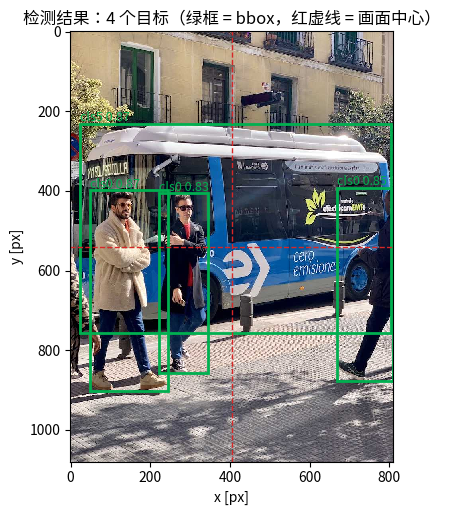

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches

# ---- 全项目统一配色（代码书写原则第 5 条）----
COLOR_BOX = "#00b050"      # bbox 框线
COLOR_CENTER = "#d62728"   # 画面中心参考线

try:
    from datatypes import DetectedTarget
    # 无模型（未安装依赖）时，退化为一条示例 bbox，使可视化仍然可见
    boxes = globals().get("detections") or [
        DetectedTarget(class_id=0, confidence=0.91, bbox=(280.0, 200.0, 120.0, 90.0))
    ]

    fig, ax = plt.subplots(figsize=(7, 5.25))
    ax.imshow(image[:, :, ::-1])                       # BGR -> RGB 供 matplotlib 显示
    for b in boxes:
        x, y, w, h = b.bbox
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False,
                                       edgecolor=COLOR_BOX, linewidth=2))
        ax.text(x, max(y - 6, 12), "cls%d %.2f" % (b.class_id, b.confidence),
                color=COLOR_BOX, fontsize=9)
    ax.axvline(image.shape[1] / 2, color=COLOR_CENTER, linestyle="--", linewidth=1)
    ax.axhline(image.shape[0] / 2, color=COLOR_CENTER, linestyle="--", linewidth=1)
    ax.set_title("检测结果：%d 个目标（绿框 = bbox，红虚线 = 画面中心）" % len(boxes))
    ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
    plt.tight_layout(); plt.show()
except ImportError as exc:
    print("[跳过] 缺少 datatypes:", exc)

## 4. 空输入与边界（「空即正常」）

设计原则第 5 条：**空 = 没目标（业务正常）、静默 = 故障**。
`detect` 在无目标时返回 `[]`（不返回 `None`），节点壳据此发送**空** `Detections`。

In [7]:
# 空数组 / 非法维数：onboard 阶段应告警并返回 []
import detector as det_mod

try:
    out = det_mod.detect(np.zeros((0, 0, 3), dtype=np.uint8))
    print("空数组 ->", out)
except RuntimeError as exc:
    print("[说明] 未调用 setup，模块级入口需先配置：", exc)

# 用实例直接验证边界
try:
    print("空数组        ->", det.detect(np.zeros((0, 0, 3), dtype=np.uint8)))
except ValueError as exc:
    print("空数组（dev 阶段抛错，符合预期）:", exc)

[说明] 未调用 setup，模块级入口需先配置： [detector] 检测器未配置；请先调用 detector.setup(...)（节点在 __init__ 中完成）
空数组（dev 阶段抛错，符合预期）: [detector] detect: image 为空数组


## 5. 阶段化参数校验（dev / onboard）

代码书写原则第 1 条：**开发阶段非法输入直接抛错**（问题尽早暴露），
**上机阶段告警并给默认值**（不因脏数据崩溃）。
由 `config.UAV_STAGE` 环境变量控制（默认 `dev`）。

In [8]:
import importlib
import warnings

# --- dev：非法参数抛 ValueError ---
det_mod.ONBOARD = False
try:
    YoloDetector(model_path="")
    print("dev: 未抛错（异常）")
except ValueError as exc:
    print("dev   ->", exc)

# --- onboard：告警并回退默认值 ---
det_mod.ONBOARD = True
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    d2 = YoloDetector(model_path=None)
    print("onboard -> 告警:", [str(x.message) for x in w])
    print("onboard -> 回退后 model_path =", d2.model_path)

det_mod.ONBOARD = False      # 还原，避免影响其它单元

dev   -> [detector] YoloDetector: model_path 必须为非空 str，实际为 ''
onboard -> 告警: ['[detector] YoloDetector: model_path 必须为非空 str，实际为 None；上机阶段按空结果处理（返回 []）']
onboard -> 回退后 model_path = yolov8n.pt


## 6. 小结

| 约定 | 取值 | 出处 |
|---|---|---|
| 输入图像 | BGR `np.ndarray` `(H, W, 3)` | ROS `bgr8` |
| 输出 bbox | `(x, y, w, h)` 左上角 + 宽高 | 数据类型.md 1.1 |
| 无目标 | 返回 `[]`，节点发空 `Detections` | 设计原则第 5 条 |
| 参数注入 | `setup(**kwargs)`，签名不含参数 | 函数接口.md 4.1 |
| 阶段校验 | `dev` 抛错 / `onboard` 兜底 | 代码书写原则第 1 条 |